In [ ]:
import numpy as np
from osgeo import gdal
import matplotlib.pyplot as plt
import os

In [3]:
os. chdir(r'E:\CTECH\GEOINT\project')
file_name= 'SentinelTinkitamAPR2021.tif'
raster_info=gdal.Info(file_name,format='JSON')
print(raster_info)

Driver: GTiff/GeoTIFF
Files: SentinelTinkitamAPR2021.tif
Size is 176, 112
Coordinate System is:
PROJCRS["WGS 84 / UTM zone 45N",
    BASEGEOGCRS["WGS 84",
        DATUM["World Geodetic System 1984",
            ELLIPSOID["WGS 84",6378137,298.257223563,
                LENGTHUNIT["metre",1]]],
        PRIMEM["Greenwich",0,
            ANGLEUNIT["degree",0.0174532925199433]],
        ID["EPSG",4326]],
    CONVERSION["UTM zone 45N",
        METHOD["Transverse Mercator",
            ID["EPSG",9807]],
        PARAMETER["Latitude of natural origin",0,
            ANGLEUNIT["degree",0.0174532925199433],
            ID["EPSG",8801]],
        PARAMETER["Longitude of natural origin",87,
            ANGLEUNIT["degree",0.0174532925199433],
            ID["EPSG",8802]],
        PARAMETER["Scale factor at natural origin",0.9996,
            SCALEUNIT["unity",1],
            ID["EPSG",8805]],
        PARAMETER["False easting",500000,
            LENGTHUNIT["metre",1],
            ID["EPSG",8806]],
  

In [ ]:
from osgeo import gdal
import os

os. chdir(r'E:\CTECH\GEOINT\project')
file_name= 'SentinelTinkitamAPR2021.tif'
ds= gdal.Open(file_name)
print('File List:', ds.GetFileList())
print('width:', ds.RasterXSize)
print('height:', ds.RasterYSize)

print(ds)

File List: ['SentinelTinkitamAPR2021.tif']
width: 176
height: 112
<osgeo.gdal.Dataset; proxy of <Swig Object of type 'GDALDatasetShadow *' at 0x000001F46B750330> >


In [14]:
gt= ds.GetGeoTransform()
print('Origin:',(gt[0],gt[3]))
print('pixelsize:', gt[1],gt[5])

Origin: (633350.0, 3012990.0)
pixelsize: 10.0 -10.0


In [2]:
from osgeo import gdal
import os

os. chdir(r'E:\CTECH\GEOINT\project')
file_name= 'SentinelTinkitamAPR2021.tif'
ds= gdal.Open(file_name)

band = ds.GetRasterBand(1)
data = band.ReadAsArray()
print(data)

[[791 771 861 ... 427 400 378]
 [839 825 818 ... 432 417 396]
 [798 857 836 ... 419 417 413]
 ...
 [416 429 402 ... 803 796 764]
 [391 400 440 ... 828 771 728]
 [456 427 456 ... 834 771 753]]


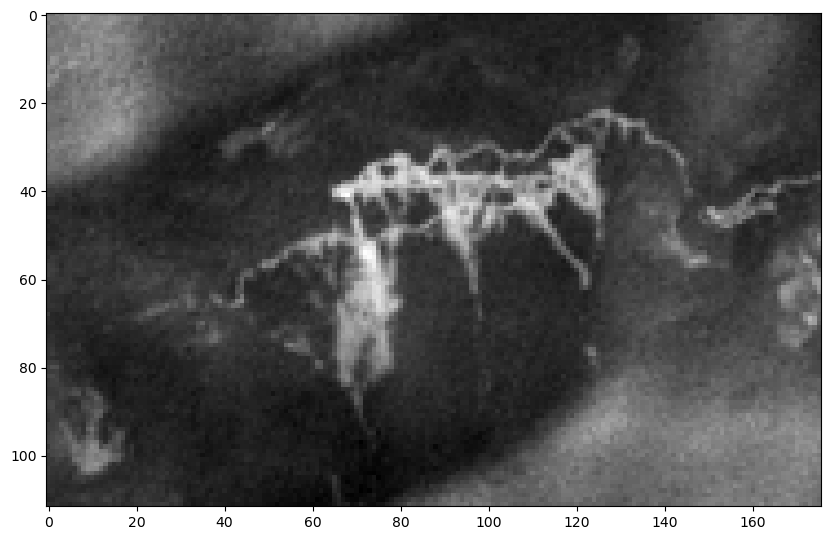

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
plt.imshow(data,cmap= 'gray')


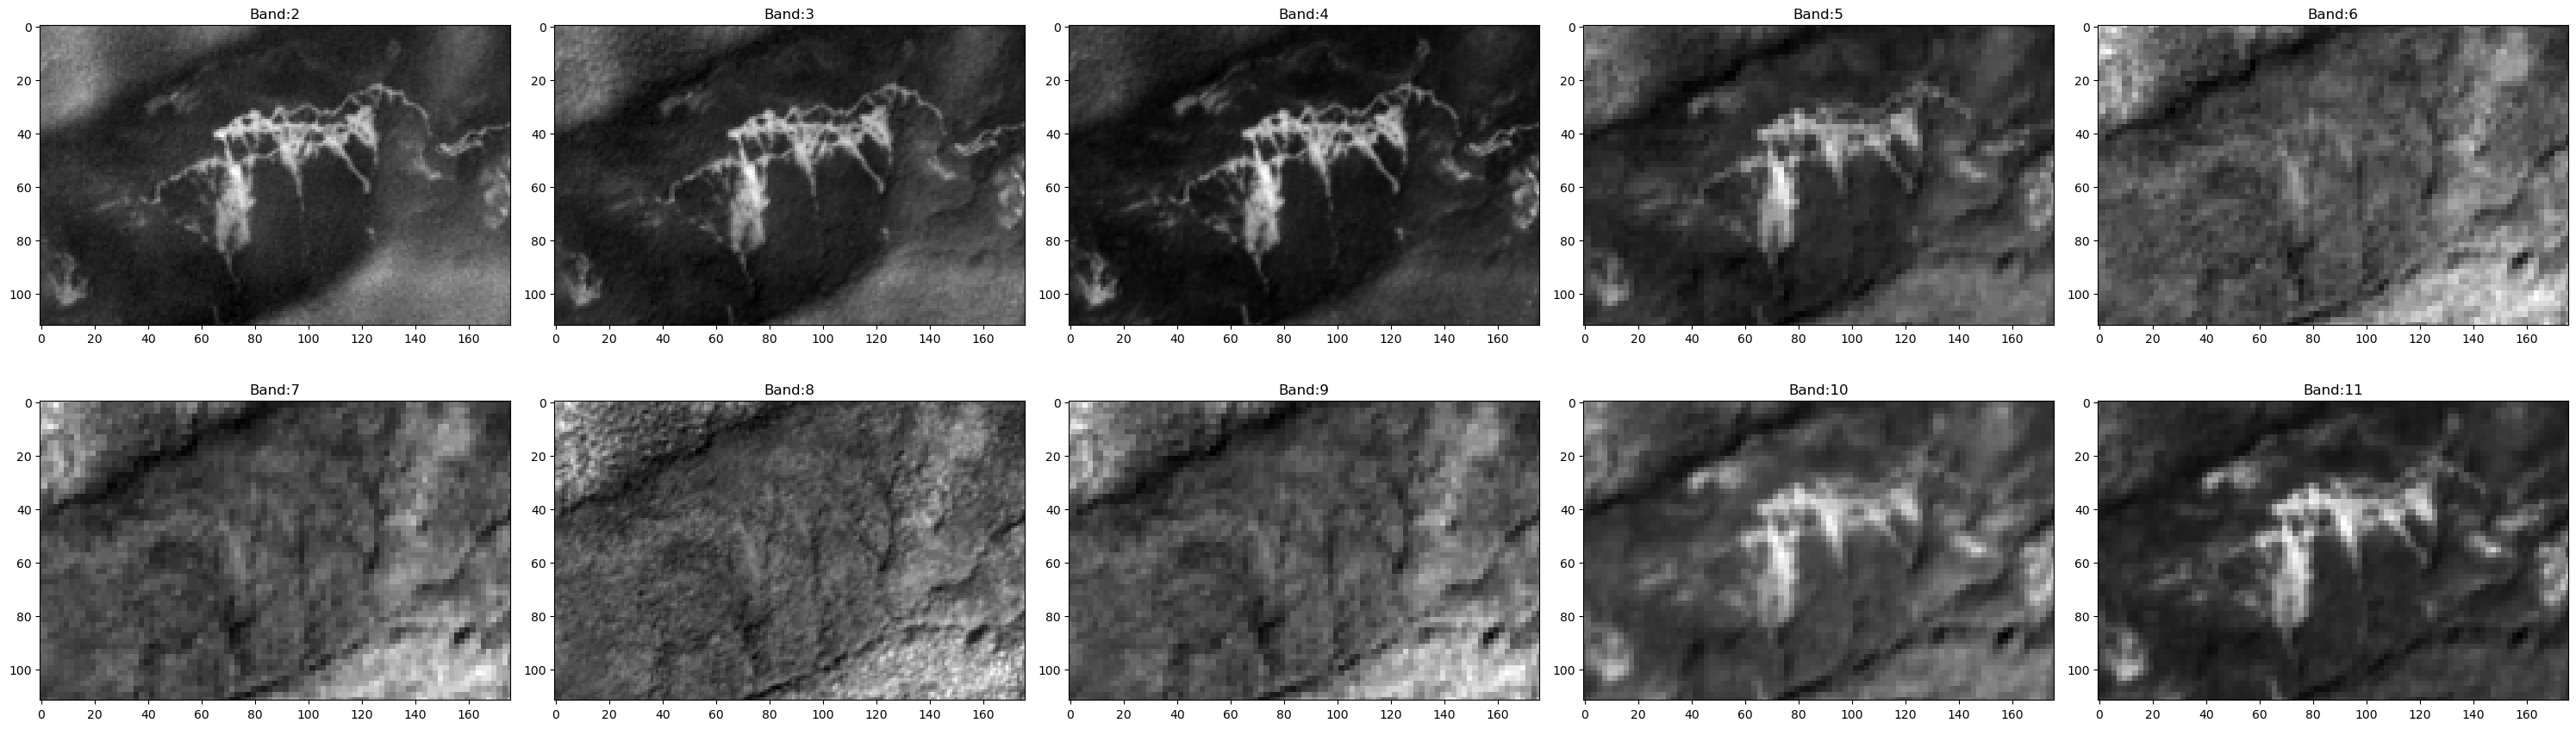

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(30,10)) #L=30, W=10
for i in range(1, ds.RasterCount+1):
    band = ds.GetRasterBand(i)
    data = band.ReadAsArray()
    
    plt.subplot(2,5,i) #2 rows 5 col
    plt.title('Band:'+str(i+1))
    plt.imshow(data,cmap= 'gray')
    plt.tight_layout()

In [4]:
multidata = ds.ReadAsArray(band_list=[3,2,1])
multidata[2]

array([[791, 771, 861, ..., 427, 400, 378],
       [839, 825, 818, ..., 432, 417, 396],
       [798, 857, 836, ..., 419, 417, 413],
       ...,
       [416, 429, 402, ..., 803, 796, 764],
       [391, 400, 440, ..., 828, 771, 728],
       [456, 427, 456, ..., 834, 771, 753]],
      shape=(112, 176), dtype=uint16)

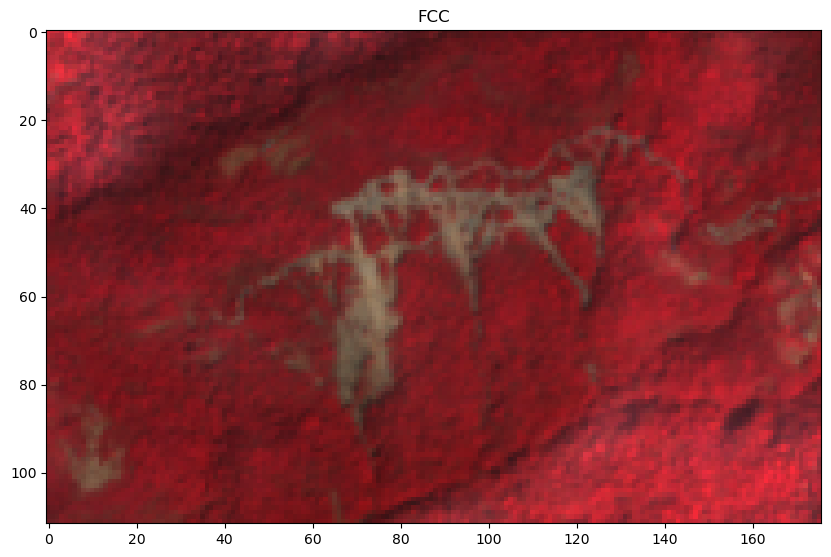

In [6]:
import numpy as np
multidata = ds.ReadAsArray(band_list=[7,3,2])
multidata = multidata.astype('float')
multidata/=np.max(multidata)

multidata = np.transpose(multidata, axes=(1,2,0))

plt.figure(figsize=(10,10))
plt.title('FCC')
plt.imshow(multidata)

<>:6: SyntaxWarning: invalid escape sequence '\C'
<>:6: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\3619120576.py:6: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"   # Replace with your actual path


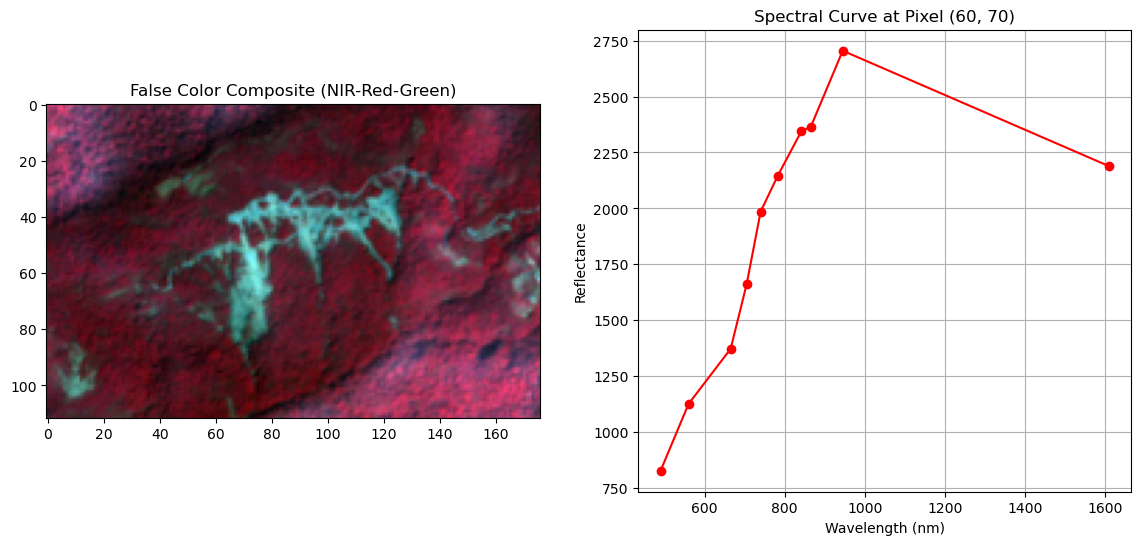

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from osgeo import gdal

# Define file path
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"   # Replace with your actual path

# Open image using GDAL
dataset = gdal.Open(image_path)

# Select bands for FCC (False Color Composite)
# Example: Sentinel-2 Bands (NIR = 8, Red = 4, Green = 3)
nir_band = dataset.GetRasterBand(7).ReadAsArray().astype(np.float32)
red_band = dataset.GetRasterBand(3).ReadAsArray().astype(np.float32)
green_band = dataset.GetRasterBand(2).ReadAsArray().astype(np.float32)

# Normalize bands to 0-1 for visualization
nir_norm = (nir_band - nir_band.min()) / (nir_band.max() - nir_band.min())
red_norm = (red_band - red_band.min()) / (red_band.max() - red_band.min())
green_norm = (green_band - green_band.min()) / (green_band.max() - green_band.min())

# Stack bands to create FCC image (NIR-Red-Green)
fcc_image = np.dstack((nir_norm, red_norm, green_norm))

# Select a point for spectral analysis (row, column)
row, col = 60, 70  # Modify as needed

# Read all bands at the selected pixel location
spectral_values = []
wavelengths = [490, 560, 665, 705, 740, 783, 842, 865, 945, 1610, 2190]  # Example Sentinel-2 Wavelengths

for band_index in range(1, dataset.RasterCount + 1):
    band_data = dataset.GetRasterBand(band_index).ReadAsArray()
    spectral_values.append(band_data[row, col])

# Convert spectral values to NumPy array
spectral_values = np.array(spectral_values)

# Display FCC image and Spectral Curve
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Display False Color Composite (FCC)
ax[0].imshow(fcc_image)
ax[0].set_title("False Color Composite (NIR-Red-Green)")


# Display Spectral Curve
ax[1].plot(wavelengths[:len(spectral_values)], spectral_values, marker="o", linestyle="-", color="red")
ax[1].set_xlabel("Wavelength (nm)")
ax[1].set_ylabel("Reflectance")
ax[1].set_title(f"Spectral Curve at Pixel ({row}, {col})")
ax[1].grid(True)

plt.show()




<>:6: SyntaxWarning: invalid escape sequence '\C'
<>:6: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\3720644229.py:6: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"   # Replace with your actual image path
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\3720644229.py:65: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend()
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\3720644229.py:74: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


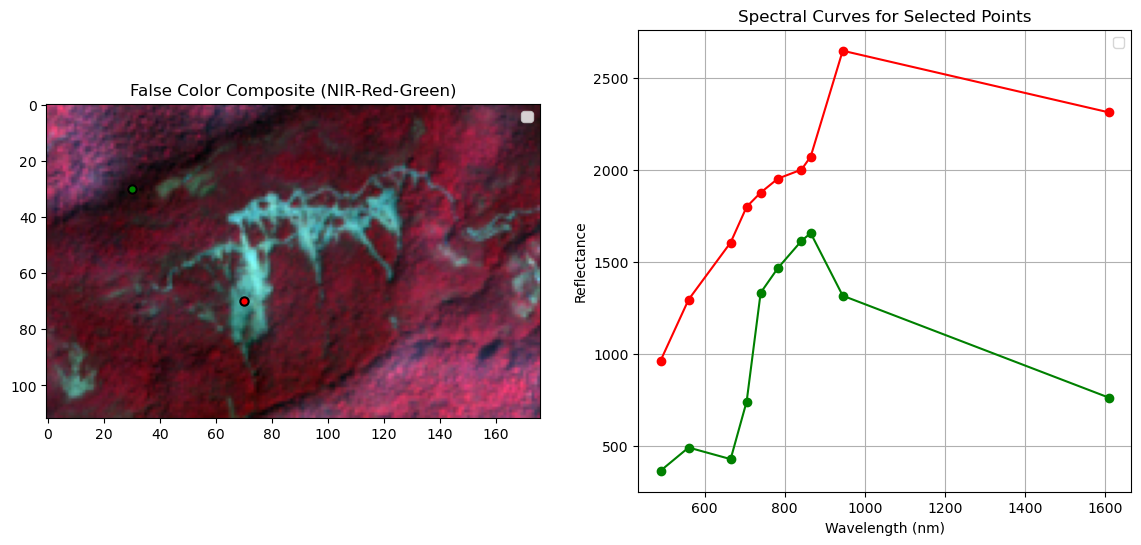

In [89]:
import numpy as np
import matplotlib.pyplot as plt
from osgeo import gdal

# Define file path
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"   # Replace with your actual image path

# Open image using GDAL
dataset = gdal.Open(image_path)

# Select bands for FCC (False Color Composite) - Sentinel-2 Example
# NIR (Band 8), Red (Band 4), Green (Band 3)
nir_band = dataset.GetRasterBand(7).ReadAsArray().astype(np.float32)
red_band = dataset.GetRasterBand(3).ReadAsArray().astype(np.float32)
green_band = dataset.GetRasterBand(2).ReadAsArray().astype(np.float32)

# Normalize bands to 0-1 for display
nir_norm = (nir_band - nir_band.min()) / (nir_band.max() - nir_band.min())
red_norm = (red_band - red_band.min()) / (red_band.max() - red_band.min())
green_norm = (green_band - green_band.min()) / (green_band.max() - green_band.min())

# Create FCC image (NIR-Red-Green)
fcc_image = np.dstack((nir_norm, red_norm, green_norm))

# Define multiple points for spectral analysis (row, col)
selected_points = {
    "Vegetation": (30, 30),
    "Landslide": (70, 70),
    
}

colors = {
    "Vegetation": "green",
    "Landslide": "red"
}

# Sentinel-2 Wavelengths (Example)
wavelengths = [490, 560, 665, 705, 740, 783, 842, 865, 945, 1610, 2190]

# Extract spectral values for selected points
spectral_curves = {}

for label, (row, col) in selected_points.items():
    spectral_values = []
    
    # Read all bands at the selected pixel location
    for band_index in range(1, dataset.RasterCount + 1):
        band_data = dataset.GetRasterBand(band_index).ReadAsArray()
        spectral_values.append(band_data[row, col])
    
    spectral_curves[label] = np.array(spectral_values)

# Display FCC Image & Spectral Curves
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Display False Color Composite (FCC)
ax[0].imshow(fcc_image)
ax[0].set_title("False Color Composite (NIR-Red-Green)")


# Overlay selected points on FCC image
for label, (row, col) in selected_points.items():
    ax[0].scatter(col, row, marker="o", color=colors[label], edgecolors="black", linewidth=1.5)

ax[0].legend()

# Display Spectral Curves for Multiple Points
for label, values in spectral_curves.items():
    ax[1].plot(wavelengths[:len(values)], values, marker="o", linestyle="-", color=colors[label])

ax[1].set_xlabel("Wavelength (nm)")
ax[1].set_ylabel("Reflectance")
ax[1].set_title("Spectral Curves for Selected Points")
ax[1].legend()
ax[1].grid(True)

plt.show()



In [65]:
import numpy as np
import rasterio
#import cv2
import matplotlib.pyplot as plt
from osgeo import gdal

# Define file path
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path

# Open image using GDAL
dataset = gdal.Open(image_path)

# Select band (Modify based on your dataset)
band_index = 4  # Example: Red Band (Sentinel-2)

# Read band as array
band = dataset.GetRasterBand(band_index).ReadAsArray().astype(np.uint8)

# Apply Histogram Equalization using OpenCV
equalized_band = cv2.equalizeHist(band)

# Display Original and Equalized Image
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(band, cmap='gray')
ax[0].set_title(f"Original Band {band_index}")
ax[0].axis("off")

ax[1].imshow(equalized_band, cmap='gray')
ax[1].set_title(f"Histogram Equalized Band {band_index}")
ax[1].axis("off")

plt.show()

# Close dataset
dataset = None


<>:8: SyntaxWarning: invalid escape sequence '\C'
<>:8: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\2146698642.py:8: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\2146698642.py:8: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path


NameError: name 'cv2' is not defined

<>:6: SyntaxWarning: invalid escape sequence '\C'
<>:6: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\3542771807.py:6: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path


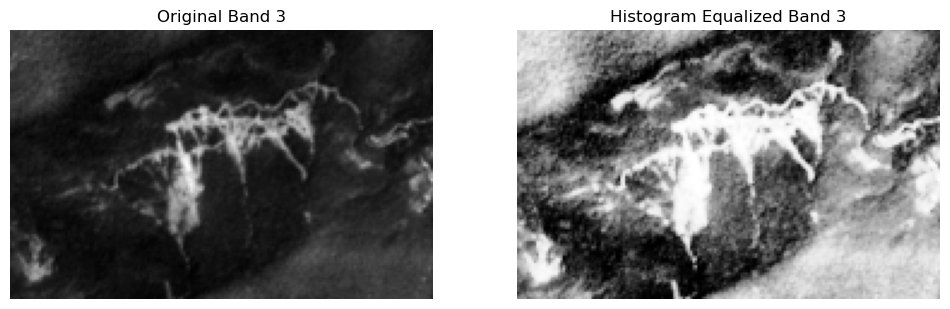

[[817. 839. 895. ... 470. 451. 446.]
 [821. 799. 800. ... 481. 459. 478.]
 [852. 797. 742. ... 464. 466. 448.]
 ...
 [455. 489. 513. ... 850. 819. 742.]
 [494. 539. 576. ... 815. 764. 676.]
 [560. 578. 585. ... 840. 789. 663.]]
[[3400.1047  3485.071   3629.6592  ... 1040.7848   811.8537   751.8164 ]
 [3417.555   3322.6172  3329.265   ... 1182.6722   904.7141  1140.9161 ]
 [3519.764   3318.4624  3105.735   ...  964.95917  989.0572   776.74536]
 ...
 [ 861.08844 1293.1907  1602.9332  ... 3515.8167  3409.2454  3105.735  ]
 [1357.175   1901.4578  2225.119   ... 3392.003   3185.7156  2827.5693 ]
 [2092.5798  2237.7913  2290.3499  ... 3486.9407  3284.6006  2769.6094 ]]


In [71]:
from osgeo import gdal
import numpy as np
import matplotlib.pyplot as plt

# Define file path
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path


# Open the image using GDAL
dataset = gdal.Open(image_path)

# Select band (Modify based on your dataset)
band_index = 3  # Example: Red Band (Sentinel-2)

# Read band as a NumPy array
band = dataset.GetRasterBand(band_index).ReadAsArray().astype('float32')

# Perform histogram equalization using NumPy
hist, bins = np.histogram(band.flatten(), bins=4096, range=[0,4096])
cdf = hist.cumsum()  # Compute the cumulative distribution function
cdf_normalized = (cdf - cdf.min()) * 4095 / (cdf.max() - cdf.min())  # Normalize CDF
equalized_band = np.interp(band.flatten(), bins[:-1], cdf_normalized).reshape(band.shape).astype('float32')

# Display Original and Equalized Image
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(band, cmap='gray')
ax[0].set_title(f"Original Band {band_index}")
ax[0].axis("off")

ax[1].imshow(equalized_band, cmap='gray')
ax[1].set_title(f"Histogram Equalized Band {band_index}")
ax[1].axis("off")

plt.show()
print(image)
print(equalized_band)




<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:7: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\1402873731.py:7: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path


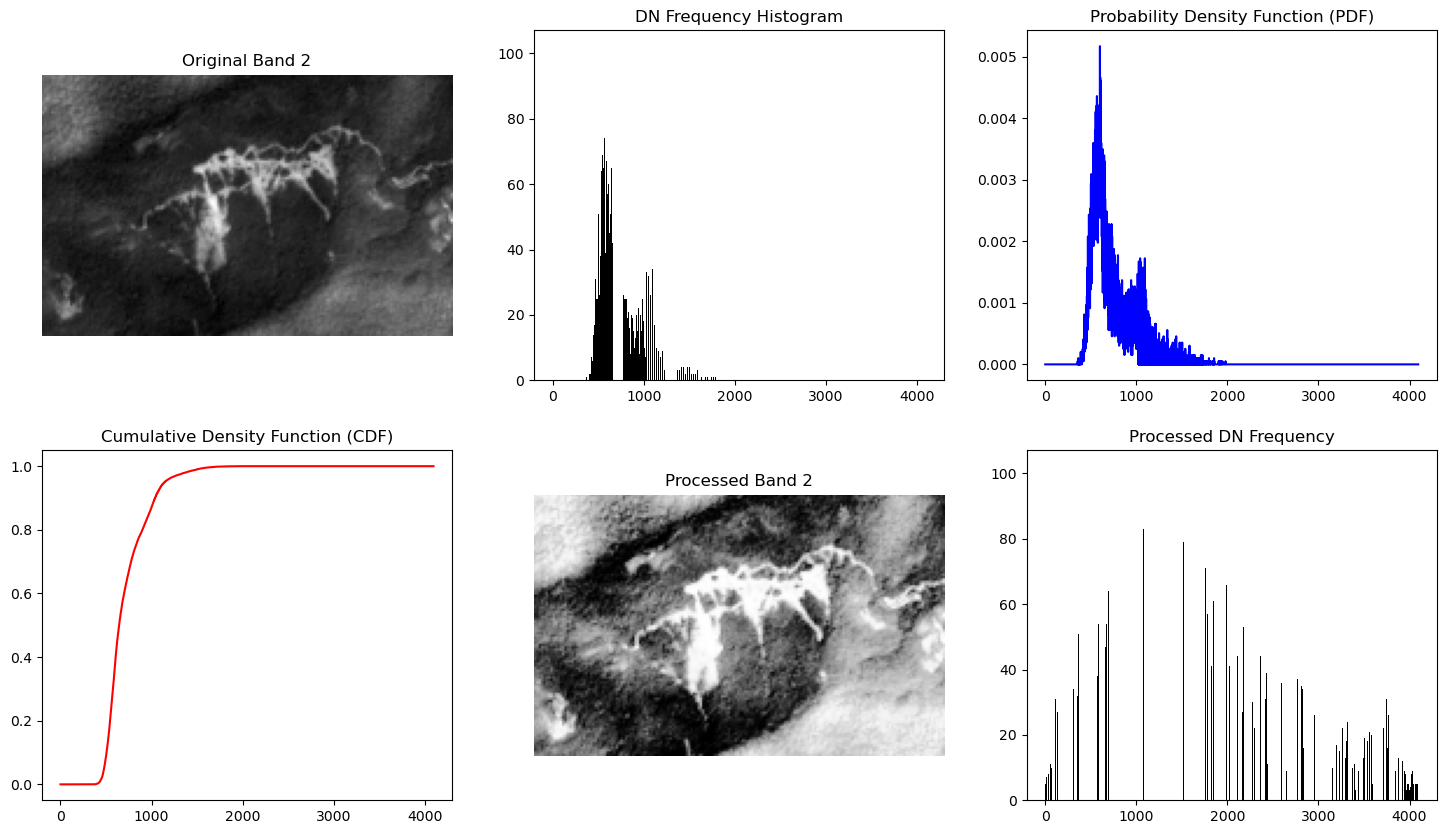

[[817. 839. 895. ... 470. 451. 446.]
 [821. 799. 800. ... 481. 459. 478.]
 [852. 797. 742. ... 464. 466. 448.]
 ...
 [455. 489. 513. ... 850. 819. 742.]
 [494. 539. 576. ... 815. 764. 676.]
 [560. 578. 585. ... 840. 789. 663.]]
[[3675.3623  3825.9749  3870.0159  ...  444.7745  1079.4247   556.9549 ]
 [3681.8022  3629.867   3651.6797  ...  662.6953   695.10297  518.10724]
 [3681.8022  3552.7947  3492.342   ...  750.1545   902.0135   750.1545 ]
 ...
 [ 976.5927  1365.4847  1544.9734  ... 3732.2834  3361.8804  3138.1428 ]
 [1676.0582  1528.7695  1848.8992  ... 3535.76    3366.0352  3080.1829 ]
 [2066.4045  2052.6936  2238.2068  ... 3513.5315  3368.3203  3361.8804 ]]


In [78]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from osgeo import gdal

# Define file path
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path

# Open image using GDAL
dataset = gdal.Open(image_path)

# Select band (Modify based on your dataset)
band_index = 2  # Example: Red Band (Sentinel-2)

# Read band as a NumPy array
band = dataset.GetRasterBand(band_index).ReadAsArray().astype('float32')

# Extract DN frequency within a range
dn_min, dn_max = band.min(), band.max()
hist, bins = np.histogram(band.flatten(), bins=4096, range=[0, 4096])

# Compute Probability Density Function (PDF)
pdf = hist / np.sum(hist)

# Compute Cumulative Density Function (CDF)
cdf = pdf.cumsum()

# Normalize CDF to stretch pixel values between 0 and 255
cdf_normalized = (cdf - cdf.min()) * 4095 / (cdf.max() - cdf.min())

# Recalculate DN values using the CDF mapping
processed_band = np.interp(band.flatten(), bins[:-1], cdf_normalized).reshape(band.shape).astype('float32')

# Display Original, PDF, CDF, and Processed Image
fig, ax = plt.subplots(2, 3, figsize=(18, 10))

ax[0, 0].imshow(band, cmap='gray')
ax[0, 0].set_title(f"Original Band {band_index}")
ax[0, 0].axis("off")

ax[0, 1].bar(range(4096), hist, color='black')
ax[0, 1].set_title("DN Frequency Histogram")

ax[0, 2].plot(pdf, color='blue')
ax[0, 2].set_title("Probability Density Function (PDF)")

ax[1, 0].plot(cdf, color='red')
ax[1, 0].set_title("Cumulative Density Function (CDF)")

ax[1, 1].imshow(processed_band, cmap='gray')
ax[1, 1].set_title(f"Processed Band {band_index}")
ax[1, 1].axis("off")

ax[1, 2].bar(range(4096), np.histogram(processed_band.flatten(), bins=4096, range=[0, 4096])[0], color='black')
ax[1, 2].set_title("Processed DN Frequency")

plt.show()

print(image)
print(processed_band)


<>:8: SyntaxWarning: invalid escape sequence '\C'
<>:8: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\2876481987.py:8: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"


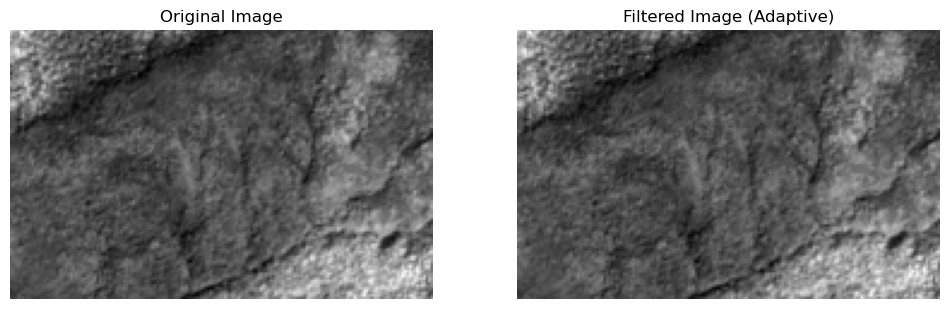

[[4012. 3812. 3758. ... 1626. 1966. 1856.]
 [3760. 3363. 3164. ... 1664. 1876. 1892.]
 [3475. 3024. 3040. ... 1860. 1924. 1836.]
 ...
 [1701. 1790. 1808. ... 3012. 2033. 2032.]
 [1772. 1740. 1830. ... 2661. 1983. 2503.]
 [1912. 1884. 2025. ... 2729. 2430. 3105.]]
[[4012.     3812.     3758.     ... 1626.0001 1965.9999 1856.0002]
 [3760.     3363.     3164.     ... 1664.0001 1876.     1891.9999]
 [3475.     3024.     3040.     ... 1860.     1924.     1836.0001]
 ...
 [1701.0001 1790.     1808.     ... 3012.     2033.     2032.    ]
 [1772.     1740.0001 1830.     ... 2661.     1983.     2503.    ]
 [1911.9999 1884.     2025.     ... 2729.     2430.     3105.    ]]


In [57]:
#import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import generic_filter
from osgeo import gdal

# Load image
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"
dataset = gdal.Open(image_path)
image = dataset.GetRasterBand(7).ReadAsArray().astype(np.float32)

# Define Adaptive Filter (Local Mean & Variance)
def adaptive_filter(pixel_values):
    """
    Adaptive filter function that reduces noise while preserving edges.
    """
    local_mean = np.mean(pixel_values)
    local_variance = np.var(pixel_values)
    
    center_pixel = pixel_values[len(pixel_values) // 2]
    
    # Noise variance (assumed)
    noise_variance = 0.01  
    
    # Compute the adaptive filter coefficient
    if local_variance > noise_variance:
        weight = noise_variance / local_variance
    else:
        weight = 0  # Avoid division by zero
    
    # Apply filter formula
    filtered_pixel = center_pixel - weight * (center_pixel - local_mean)
    
    return filtered_pixel

# Apply Adaptive Filter using a 5x5 kernel
filtered_image = generic_filter(image, adaptive_filter, size=(3, 3))

# Display Original and Filtered Images
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(image, cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(filtered_image, cmap='gray')
ax[1].set_title("Filtered Image (Adaptive)")
ax[1].axis("off")

plt.show()

print(image)

print(filtered_image)


<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:7: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\417187537.py:7: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path


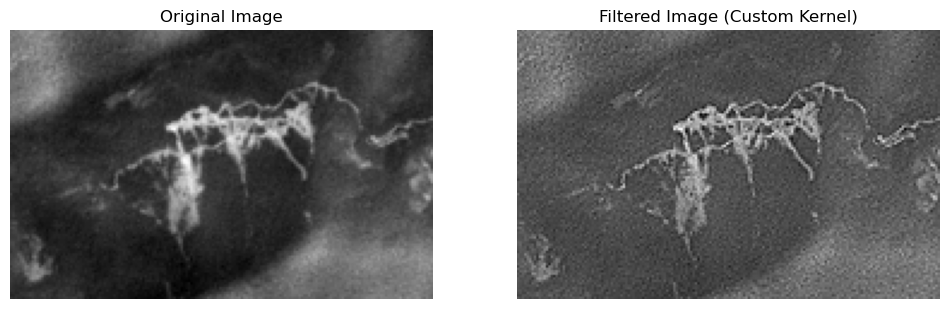

[[791. 771. 861. ... 427. 400. 378.]
 [839. 825. 818. ... 432. 417. 396.]
 [798. 857. 836. ... 419. 417. 413.]
 ...
 [416. 429. 402. ... 803. 796. 764.]
 [391. 400. 440. ... 828. 771. 728.]
 [456. 427. 456. ... 834. 771. 753.]]
[[ 763.  607. 1028. ...  454.  378.  338.]
 [ 942.  840.  714. ...  448.  440.  376.]
 [ 655. 1059.  921. ...  370.  445.  476.]
 ...
 [ 391.  477.  315. ...  822.  862.  747.]
 [ 292.  313.  497. ...  907.  732.  624.]
 [ 550.  396.  532. ...  992.  726.  760.]]


In [58]:

import numpy as np
import matplotlib.pyplot as plt
from osgeo import gdal
from scipy.signal import convolve2d

# Load image
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path
dataset = gdal.Open(image_path)
image = dataset.GetRasterBand(1).ReadAsArray().astype(np.float32)

# Define a custom kernel (3x3 sharpening filter)
custom_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

# Apply custom kernel using 2D convolution
filtered_image = convolve2d(image, custom_kernel, mode="same", boundary="symm")

# Display Original and Filtered Images
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(image, cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(filtered_image, cmap='gray')
ax[1].set_title("Filtered Image (Custom Kernel)")
ax[1].axis("off")

plt.show()

# Close dataset
dataset = None
print(image)
print(filtered_image)


<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:7: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\1945670321.py:7: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path


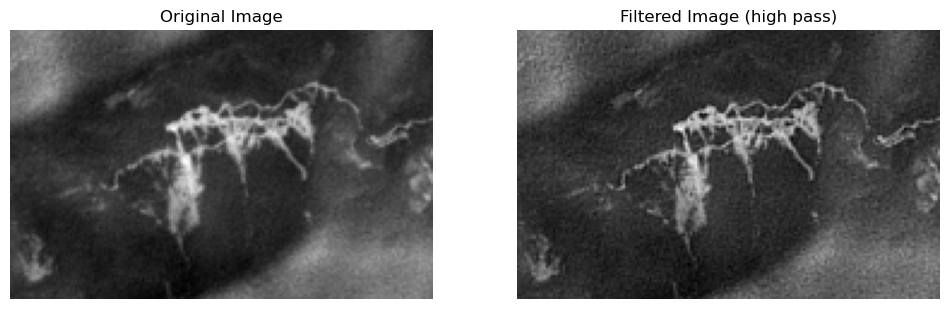

[[791. 771. 861. ... 427. 400. 378.]
 [839. 825. 818. ... 432. 417. 396.]
 [798. 857. 836. ... 419. 417. 413.]
 ...
 [416. 429. 402. ... 803. 796. 764.]
 [391. 400. 440. ... 828. 771. 728.]
 [456. 427. 456. ... 834. 771. 753.]]
[[6238. 5779. 7222. ... 3463. 3145. 2905.]
 [6954. 6629. 6464. ... 3529. 3390. 3124.]
 [6161. 7197. 6869. ... 3273. 3397. 3452.]
 ...
 [3273. 3496. 3013. ... 6471. 6475. 6087.]
 [2865. 2983. 3646. ... 6936. 6059. 5548.]
 [3892. 3350. 3851. ... 7054. 6064. 6020.]]


In [59]:

import numpy as np
import matplotlib.pyplot as plt
from osgeo import gdal
from scipy.signal import convolve2d

# Load image
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path
dataset = gdal.Open(image_path)
image = dataset.GetRasterBand(1).ReadAsArray().astype(np.float32)

# Define a custom kernel (3x3 sharpening filter)
custom_kernel = np.array([
    [-1, -1,  -1],
    [-1,  16, -1],
    [-1, -1,  -1]
], dtype=np.float32)

# Apply custom kernel using 2D convolution
filtered_image = convolve2d(image, custom_kernel, mode="same", boundary="symm")

# Display Original and Filtered Images
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(image, cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(filtered_image, cmap='gray')
ax[1].set_title("Filtered Image (high pass)")
ax[1].axis("off")

plt.show()

# Close dataset
dataset = None
print(image)
print(filtered_image)

<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:7: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\4017408573.py:7: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path


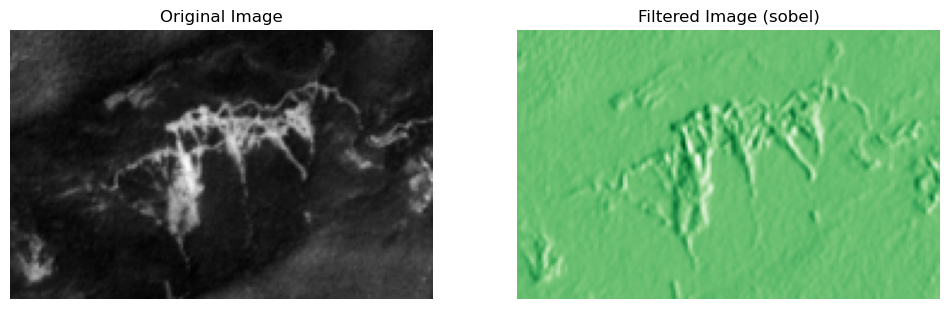

[[817. 839. 895. ... 470. 451. 446.]
 [821. 799. 800. ... 481. 459. 478.]
 [852. 797. 742. ... 464. 466. 448.]
 ...
 [455. 489. 513. ... 850. 819. 742.]
 [494. 539. 576. ... 815. 764. 676.]
 [560. 578. 585. ... 840. 789. 663.]]
[[  44.  213.  -60. ... -158.  -75.    4.]
 [ -77.  -74.  -84. ... -108.  -46.   15.]
 [-175. -361. -154. ...  -58.  -81.  -39.]
 ...
 [  95.  182.   48. ...  -57. -489. -363.]
 [ 142.  247.   45. ... -244. -563. -379.]
 [  99.  157.   27. ... -348. -670. -466.]]


In [60]:
import numpy as np
import matplotlib.pyplot as plt
from osgeo import gdal
from scipy.signal import convolve2d

# Load image
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Replace with actual image path
dataset = gdal.Open(image_path)
image = dataset.GetRasterBand(3).ReadAsArray().astype(np.float32)

# Define a custom kernel (3x3 sharpening filter)
custom_kernel = np.array([
    [1, 0, -1],
    [2, 0, -2],
    [1, 0, -1]
], dtype=np.float32)

# Apply custom kernel using 2D convolution
filtered_image = convolve2d(image, custom_kernel, mode="same", boundary="symm")

# Display Original and Filtered Images
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(image, cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(filtered_image, cmap='Greens')
ax[1].set_title("Filtered Image (sobel)")
ax[1].axis("off")

plt.show()

# Close dataset
dataset = None
print(image)
print(filtered_image)

<>:6: SyntaxWarning: invalid escape sequence '\C'
<>:6: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\3039676274.py:6: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Near-Infrared band (Band 8 for Sentinel-2)


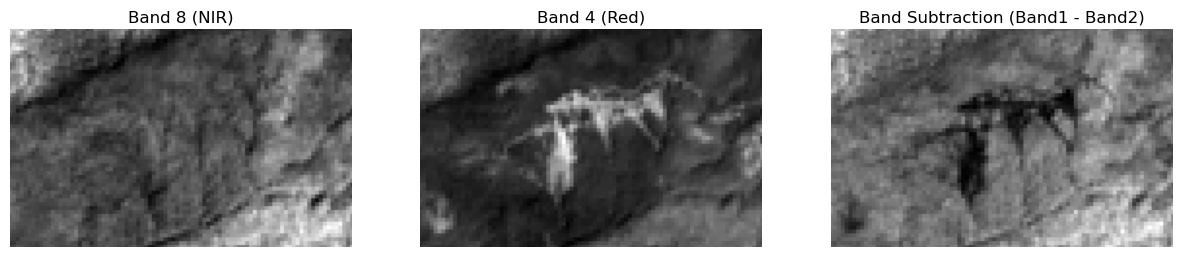

[[3772. 3719. 3719. ... 1891. 1891. 1999.]
 [3835. 3508. 3508. ... 1987. 1987. 1966.]
 [3835. 3508. 3508. ... 1987. 1987. 1966.]
 ...
 [1959. 1951. 1951. ... 2541. 2541. 3017.]
 [1959. 1951. 1951. ... 2541. 2541. 3017.]
 [2060. 2180. 2180. ... 2777. 2777. 3635.]]
[[1637. 1516. 1516. ...  797.  797.  779.]
 [1566. 1442. 1442. ...  883.  883.  855.]
 [1566. 1442. 1442. ...  883.  883.  855.]
 ...
 [ 868.  930.  930. ... 1222. 1222. 1139.]
 [ 868.  930.  930. ... 1222. 1222. 1139.]
 [ 944. 1035. 1035. ... 1183. 1183. 1283.]]
[[2135. 2203. 2203. ... 1094. 1094. 1220.]
 [2269. 2066. 2066. ... 1104. 1104. 1111.]
 [2269. 2066. 2066. ... 1104. 1104. 1111.]
 ...
 [1091. 1021. 1021. ... 1319. 1319. 1878.]
 [1091. 1021. 1021. ... 1319. 1319. 1878.]
 [1116. 1145. 1145. ... 1594. 1594. 2352.]]


In [64]:
from osgeo import gdal
import numpy as np
import matplotlib.pyplot as plt

# Define file path
image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Near-Infrared band (Band 8 for Sentinel-2)

# Open image
dataset = gdal.Open(image_path)

# Select bands (modify based on your dataset)
band1_index = 8  # Example: Near-Infrared (NIR) Band
band2_index = 4  # Example: Red Band

# Read bands as arrays
band1 = dataset.GetRasterBand(band1_index).ReadAsArray().astype(np.float32)
band2 = dataset.GetRasterBand(band2_index).ReadAsArray().astype(np.float32)

# Apply subtraction: Band1 - Band2
subtracted_image = band1 - band2

# Display Original Bands and Subtracted Image
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(band1, cmap='gray')
ax[0].set_title(f"Band {band1_index} (NIR)")
ax[0].axis("off")

ax[1].imshow(band2, cmap='gray')
ax[1].set_title(f"Band {band2_index} (Red)")
ax[1].axis("off")

ax[2].imshow(subtracted_image, cmap='gray')
ax[2].set_title("Band Subtraction (Band1 - Band2)")
ax[2].axis("off")

plt.show()


print(band1)
print(band2)
print (subtracted_image)


<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:7: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_7120\645473656.py:7: SyntaxWarning: invalid escape sequence '\C'
  image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Near-Infrared band (Band 8 for Sentinel-2)


[[0.66162767 0.63921737 0.61530196 ... 0.55152672 0.6268101  0.61251086]
 [0.64156298 0.61604998 0.59636731 ... 0.55151515 0.60685225 0.59662447]
 [0.60619367 0.58283172 0.60761502 ... 0.60068847 0.61004184 0.60770578]
 ...
 [0.57792208 0.57086441 0.55794916 ... 0.55981357 0.4256662  0.46503244]
 [0.56398941 0.52698552 0.52119701 ... 0.5310702  0.44375683 0.57470903]
 [0.54692557 0.53046304 0.55172414 ... 0.52927991 0.50978565 0.64808917]]


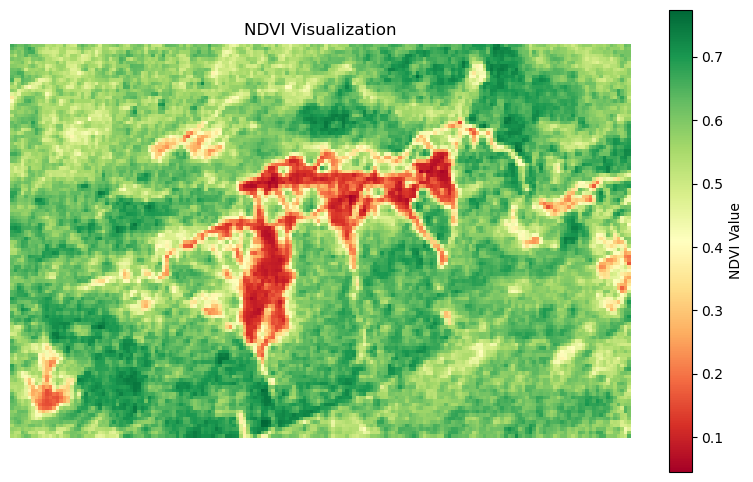

'driver = gdal.GetDriverByName("GTiff")\nndvi_dataset = driver.Create(ndvi_output_path, red_dataset.RasterXSize, red_dataset.RasterYSize, 1, gdal.GDT_Float32)\nndvi_dataset.SetGeoTransform(red_dataset.GetGeoTransform())  # Copy georeferencing\nndvi_dataset.SetProjection(red_dataset.GetProjection())  # Copy projection\n\nndvi_band = ndvi_dataset.GetRasterBand(1)\nndvi_band.WriteArray(ndvi)\nndvi_band.SetNoDataValue(-9999)  # Set NoData value\nndvi_band.FlushCache()\n\n# Close datasets\nnir_dataset = None\nred_dataset = None\nndvi_dataset = None\n\nprint(f"NDVI image saved at {ndvi_output_path}")'

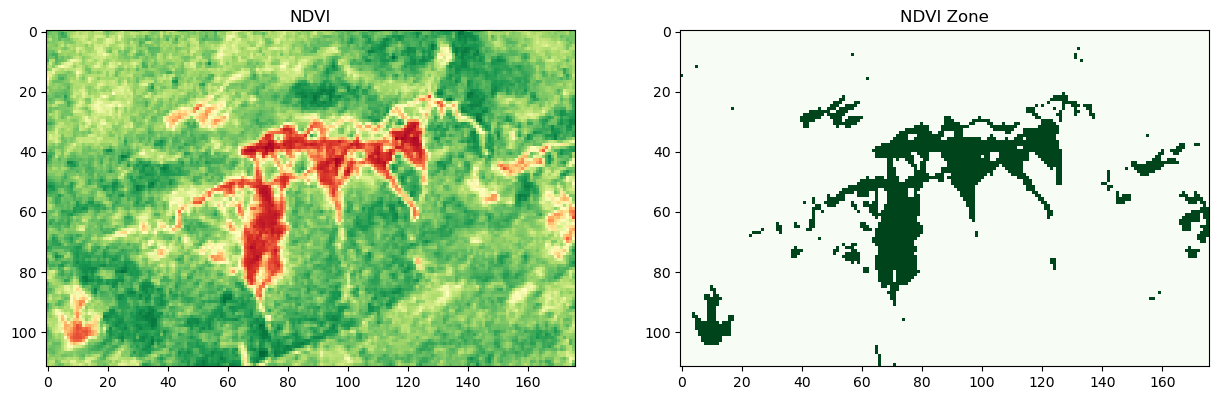

In [63]:
from osgeo import gdal
import numpy as np
import matplotlib.pyplot as plt

# Define file paths

image_path = "E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif"  # Near-Infrared band (Band 8 for Sentinel-2)

# Open the NIR and Red bands
image_dataset = gdal.Open(image_path)

# Read data as arrays
nir_band = image_dataset.GetRasterBand(7).ReadAsArray().astype('float')
red_band = image_dataset.GetRasterBand(3).ReadAsArray().astype('float')

# Compute NDVI
ndvi = (nir_band - red_band) / (nir_band + red_band )  # Adding a small value to avoid division by zero

print(ndvi)

def classify_ndvi(ndvi_array):
    """
    Classifies NDVI values into categories.
    """
    ndvi_class = np.zeros_like(ndvi_array, dtype=np.uint8)

    # Define NDVI classes
    ndvi_class[(ndvi_array <= -1.0)] = 1   # No data
    ndvi_class[(ndvi_array > -1.0) & (ndvi_array < 0.0)] = 1  # Water
    ndvi_class[(ndvi_array >= 0.0) & (ndvi_array < 0.2)] = 1  # Barren land (rock, sand, snow)
    ndvi_class[(ndvi_array >= 0.2) & (ndvi_array < 0.4)] = 1  # Sparse vegetation
    ndvi_class[(ndvi_array >= 0.4) & (ndvi_array < 0.6)] = 0  # Moderate vegetation
    ndvi_class[(ndvi_array >= 0.6) & (ndvi_array <= 1.0)] = 0  # Dense vegetation

    return ndvi_class

# Apply classification
ndvi_classes = classify_ndvi(ndvi)

plt.figure(figsize=(10, 6))
plt.imshow(ndvi, cmap='RdYlGn')  # Red-Yellow-Green colormap
plt.colorbar(label="NDVI Value")
plt.title("NDVI Visualization")
plt.axis("off")  # Hide axis
plt.show()

fig, ax = plt.subplots(1,2,figsize=(15, 10))

ax[0].imshow(ndvi, cmap='RdYlGn')
ax[0].set_title('NDVI')

ax[1].imshow(ndvi_classes, cmap='Greens')
ax[1].set_title('NDVI Zone')

# Save NDVI output
'''driver = gdal.GetDriverByName("GTiff")
ndvi_dataset = driver.Create(ndvi_output_path, red_dataset.RasterXSize, red_dataset.RasterYSize, 1, gdal.GDT_Float32)
ndvi_dataset.SetGeoTransform(red_dataset.GetGeoTransform())  # Copy georeferencing
ndvi_dataset.SetProjection(red_dataset.GetProjection())  # Copy projection

ndvi_band = ndvi_dataset.GetRasterBand(1)
ndvi_band.WriteArray(ndvi)
ndvi_band.SetNoDataValue(-9999)  # Set NoData value
ndvi_band.FlushCache()

# Close datasets
nir_dataset = None
red_dataset = None
ndvi_dataset = None

print(f"NDVI image saved at {ndvi_output_path}")'''

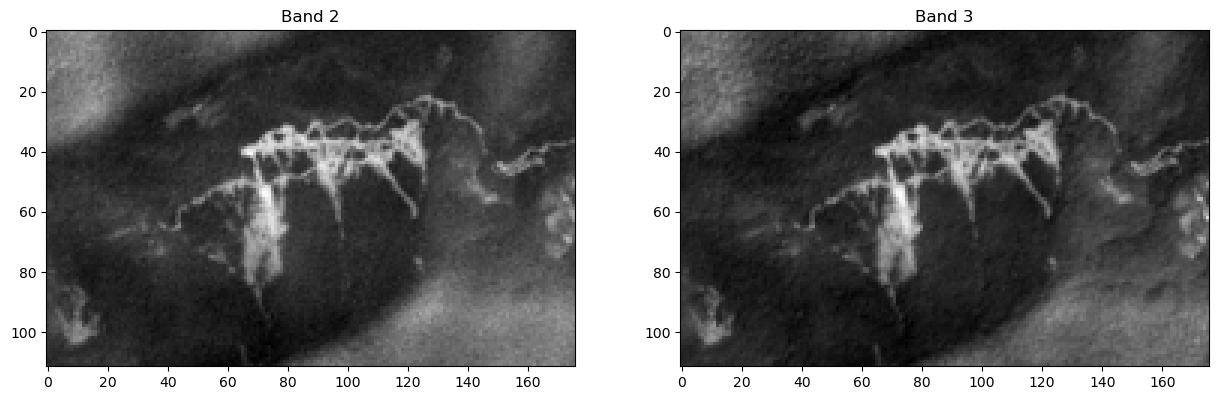

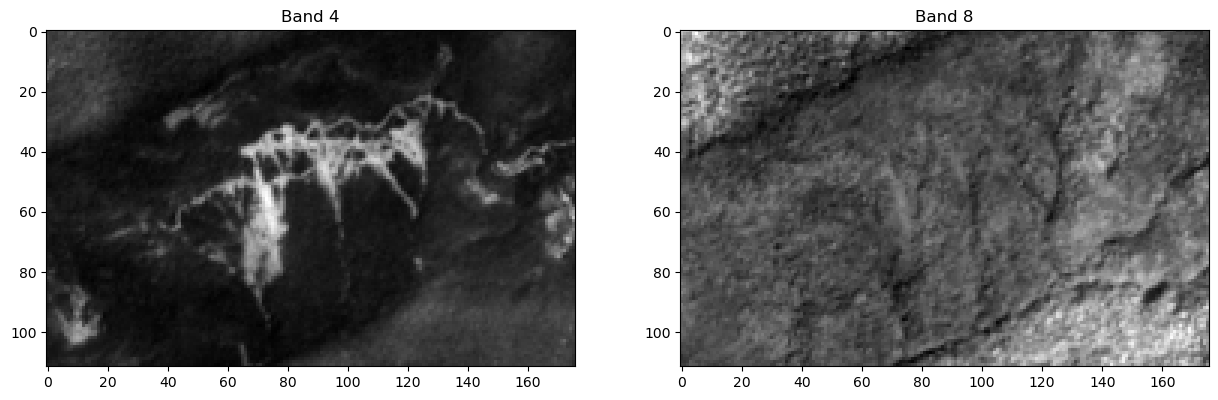

In [ ]:
import rasterio
import matplotlib.pyplot as plt

# Load the multispectral image
img_path = r'E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif'
img = rasterio.open(img_path)

# Get individual bands
band2 = img.read(1)
band3 = img.read(2)
band4 = img.read(3)
band8 = img.read(7)

# Create subplots for each band
fig, axs = plt.subplots(1,2, figsize=(15, 10))

# Display Band 2
axs[0].imshow(band2, cmap='gray')
axs[0].set_title('Band 2')

# Display Band 3
axs[1].imshow(band3, cmap='gray')
axs[1].set_title('Band 3')

# Create subplots for each band
fig, axs1 = plt.subplots(1,2, figsize=(15, 10))

# Display Band 4
axs1[0].imshow(band4, cmap='gray')
axs1[0].set_title('Band 4')

# Display Band 8
axs1[1].imshow(band8, cmap='gray')
axs1[1].set_title('Band 8')

plt.show()

In [ ]:
import rasterio

# Load the multispectral image
img_path = r'E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif'
img = rasterio.open(img_path)

print(img)
data = img.read(7) # as per specific band it is IR band 08 - denote by 7
#print(data)

num_bands = img.count
print('Number of bands in image: ', num_bands)

# row and column
rows, cols = img.shape
print('Image size is: {0} rows x {1} columns.'.format(rows, cols))

#min & max value for specific bands
min_value = data.min()
max_value = data.max()
print("Data minimum value: ", min_value)
print("Data maximum value: ", max_value)

<open DatasetReader name='E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif' mode='r'>
Number of bands in image:  10
Image size is: 112 rows x 176 columns.
Data minimum value:  987
Data maximum value:  4692


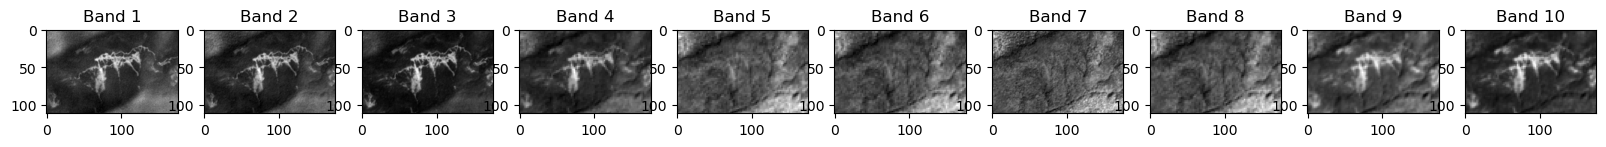

In [ ]:
from osgeo import gdal
import matplotlib.pyplot as plt

# Open the image file
ds = gdal.Open(r'E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif')

# Get the number of bands in the image
num_bands = ds.RasterCount

# Create subplots for each band
fig, axs = plt.subplots(1, num_bands, figsize=(20, 20))

# Loop through each band and display it
for i in range(1, num_bands + 1):
    band = ds.GetRasterBand(i).ReadAsArray()
    axs[i - 1].imshow(band, cmap='gray')  # You can choose any colormap here
    axs[i - 1].set_title('Band {}'.format(i))

plt.show()

<>:11: SyntaxWarning: invalid escape sequence '\C'
<>:11: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_9384\3446253378.py:11: SyntaxWarning: invalid escape sequence '\C'
  sat_data = rasterio.open('E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif')


Text(0.5, 1.0, 'False color composite')

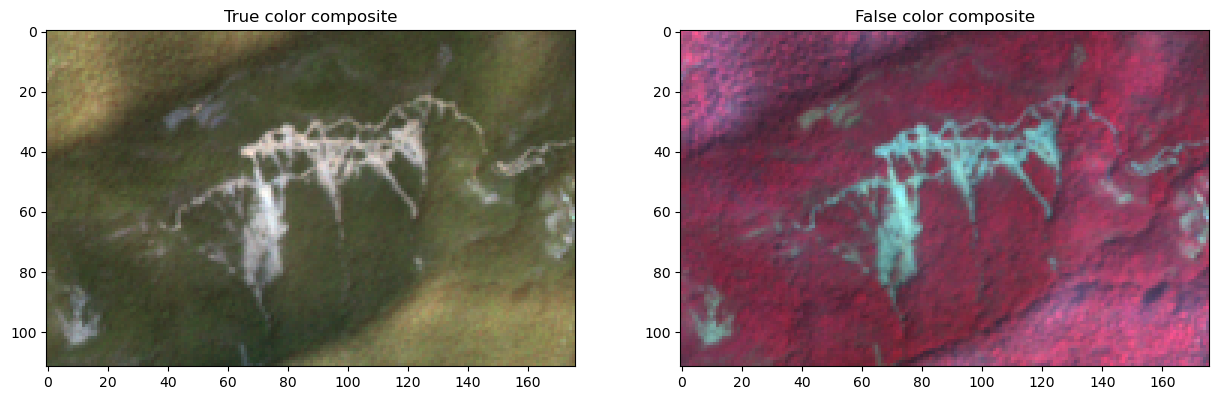

In [ ]:
import rasterio
from rasterio.plot import show
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import imageio
import rasterio

# Load Sentinel data bands
sat_data = rasterio.open('E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif')

# Read the individual bands
blue_band = sat_data.read(1).astype('float32')
green_band = sat_data.read(2).astype('float32')
red_band = sat_data.read(3).astype('float32')
NIR_band = sat_data.read(7).astype('float32')

# Normalize data (optional)
blue_band /= np.max(blue_band)
green_band /= np.max(green_band)
red_band /= np.max(red_band)
NIR_band /= np.max(NIR_band)

truecolor = np.dstack((blue_band, green_band, red_band))
Falsecolor= np.dstack((NIR_band, red_band, green_band))

# Create subplots for each band
fig, axs1 = plt.subplots(1,2, figsize=(15, 10))

# Display Band 4
axs1[0].imshow(truecolor)
axs1[0].set_title('True color composite')

# Display Band 8
axs1[1].imshow(Falsecolor)
axs1[1].set_title('False color composite')

Extract the DN values of all bands – Export to excel

In [ ]:
import pandas as pd
import numpy as np
import imageio
import rasterio
import openpyxl

ds = rasterio.open('E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif')

print("Band 2, Blue")
data_b = ds.read(1)
df_b=pd.DataFrame(data_b)
print(df_b)

print("-----------------------------------------------------")

print("Band 3, Green")
data_g = ds.read(2)
df_g=pd.DataFrame(data_g)
print(df_g)

print("-----------------------------------------------------")

print("Band 4, Red")
data_r = ds.read(3)
df_r=pd.DataFrame(data_r)
print(df_r)

print("-----------------------------------------------------")

print("Band 8, NIR")
data_nir = ds.read(4)
df_nir=pd.DataFrame(data_nir)
print(df_nir)

print("-----------------------------------------------------")

#save to Excel

file_path = "E:\CTECH\GEOINT\project\Landslide.xlsx"
excel_writer=pd.ExcelWriter(file_path, engine='openpyxl')

df_b.to_excel(excel_writer, sheet_name= 'Landslide2023 Blue')
df_g.to_excel(excel_writer, sheet_name= 'Landslide2023 Green')
df_r.to_excel(excel_writer, sheet_name= 'Landslide2023 Red')
df_nir.to_excel(excel_writer, sheet_name= 'Landslide2023 NIR')
excel_writer.close()

<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:39: SyntaxWarning: invalid escape sequence '\C'
<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:39: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_2600\3474106135.py:7: SyntaxWarning: invalid escape sequence '\C'
  ds = rasterio.open('E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif')
C:\Users\ghosh\AppData\Local\Temp\ipykernel_2600\3474106135.py:39: SyntaxWarning: invalid escape sequence '\C'
  file_path = "E:\CTECH\GEOINT\project\Landslide.xlsx"


Band 2, Blue
     0    1    2    3    4    5    6    7    8    9    ...  166  167  168  \
0    791  771  861  827  914  902  897  918  948  942  ...  515  544  486   
1    839  825  818  854  888  894  872  904  999  962  ...  563  561  472   
2    798  857  836  793  851  892  856  932  893  879  ...  578  557  515   
3    841  767  791  802  794  850  940  891  839  872  ...  589  540  518   
4    814  767  799  864  818  839  888  868  919  906  ...  605  590  599   
..   ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...   
107  453  433  425  412  398  417  433  424  402  416  ...  851  836  860   
108  453  450  416  429  422  424  434  416  414  455  ...  882  857  835   
109  416  429  402  410  470  461  453  474  511  494  ...  789  855  924   
110  391  400  440  445  444  461  472  488  529  504  ...  849  857  861   
111  456  427  456  425  427  410  441  442  459  491  ...  869  832  858   

     169  170  171  172  173  174  175  
0    478  457  415  4

In [ ]:
#Subset image

import rasterio
from rasterio.plot import show
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import imageio


# Load Sentinel data bands
sat_data = rasterio.open("E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif")

# Read the individual bands
blue_band_2 = sat_data.read(1)
green_band_3 = sat_data.read(2)
red_band_4 = sat_data.read(3)
rededge1_band_5 = sat_data.read(4)
rededge2_band_6 = sat_data.read(5)
rededge3_band_7 = sat_data.read(6)
NIR_band_8 = sat_data.read(7)
rededge4_band_8A = sat_data.read(8)
SWIR1_band_11 = sat_data.read(9)
SWIR2_band_12 = sat_data.read(10)

# Create a composite
composite = np.dstack((blue_band_2, green_band_3, red_band_4,rededge1_band_5, rededge2_band_6,rededge3_band_7, NIR_band_8, rededge4_band_8A, SWIR1_band_11, SWIR2_band_12))

truecolor = np.dstack((NIR_band_8, red_band_4, green_band_3, blue_band_2))
# Create a composite
subset = truecolor[20:30, 50:60] # y-Axis, X-Axis

# Save the subset image
imageio.imwrite('E:\CTECH\GEOINT\project\SubLandslide2021.tiff', subset)


<>:12: SyntaxWarning: invalid escape sequence '\C'
<>:34: SyntaxWarning: invalid escape sequence '\C'
<>:12: SyntaxWarning: invalid escape sequence '\C'
<>:34: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_8516\4174572581.py:12: SyntaxWarning: invalid escape sequence '\C'
  sat_data = rasterio.open("E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif")
C:\Users\ghosh\AppData\Local\Temp\ipykernel_8516\4174572581.py:34: SyntaxWarning: invalid escape sequence '\C'
  imageio.imwrite('E:\CTECH\GEOINT\project\SubLandslide2021.tiff', subset)


<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:7: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_8516\4022412055.py:7: SyntaxWarning: invalid escape sequence '\C'
  sat_data = rasterio.open('E:\CTECH\GEOINT\project\SubLandslide2021.tiff')
c:\Users\ghosh\miniconda3\envs\Raster\Lib\site-packages\rasterio\__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


Text(0.5, 1.0, 'Band 8, NIR')

<Figure size 1920x1440 with 0 Axes>

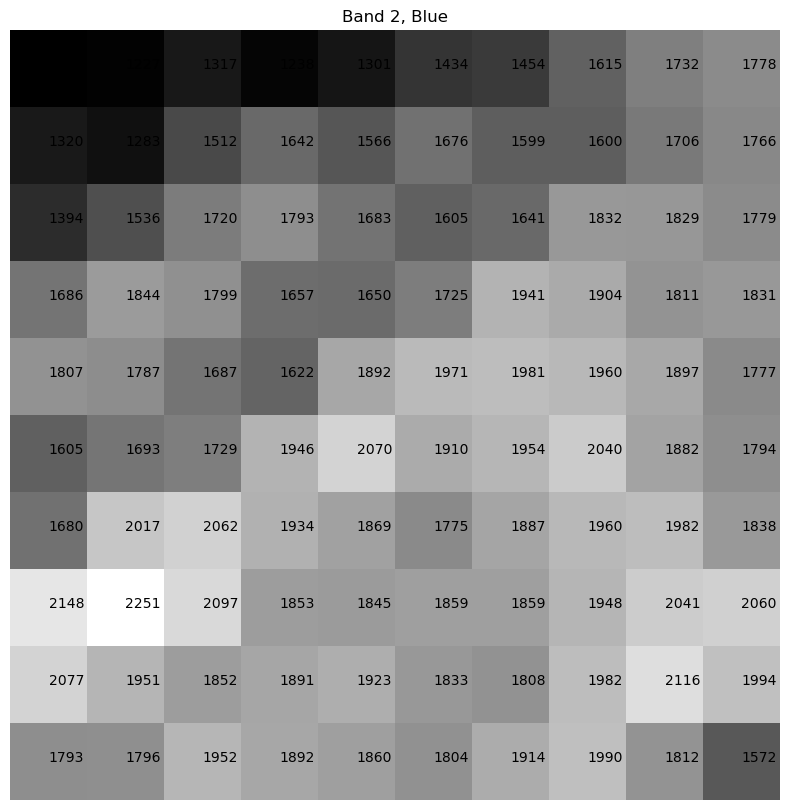

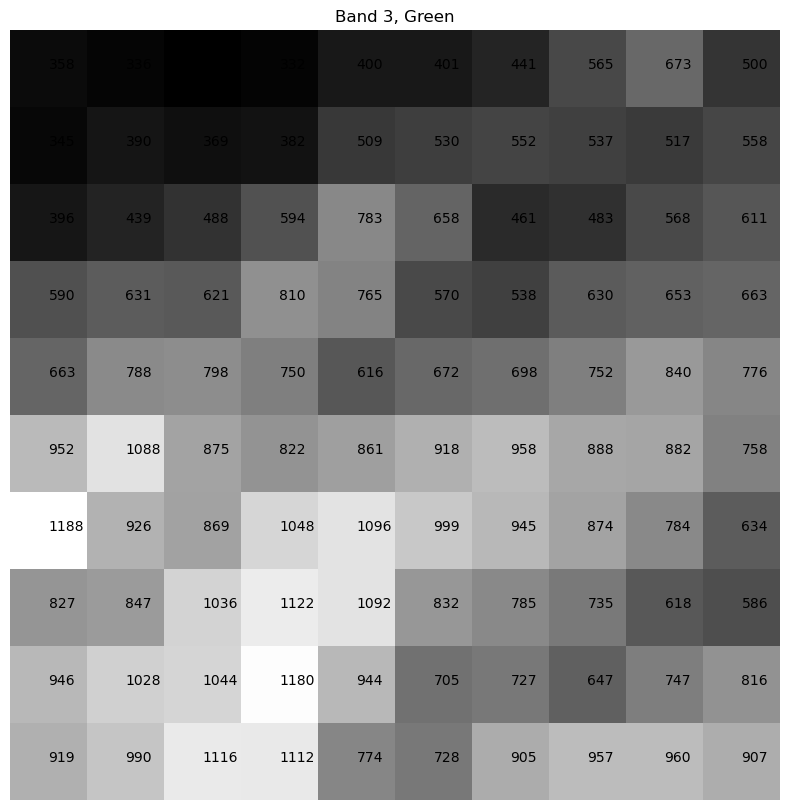

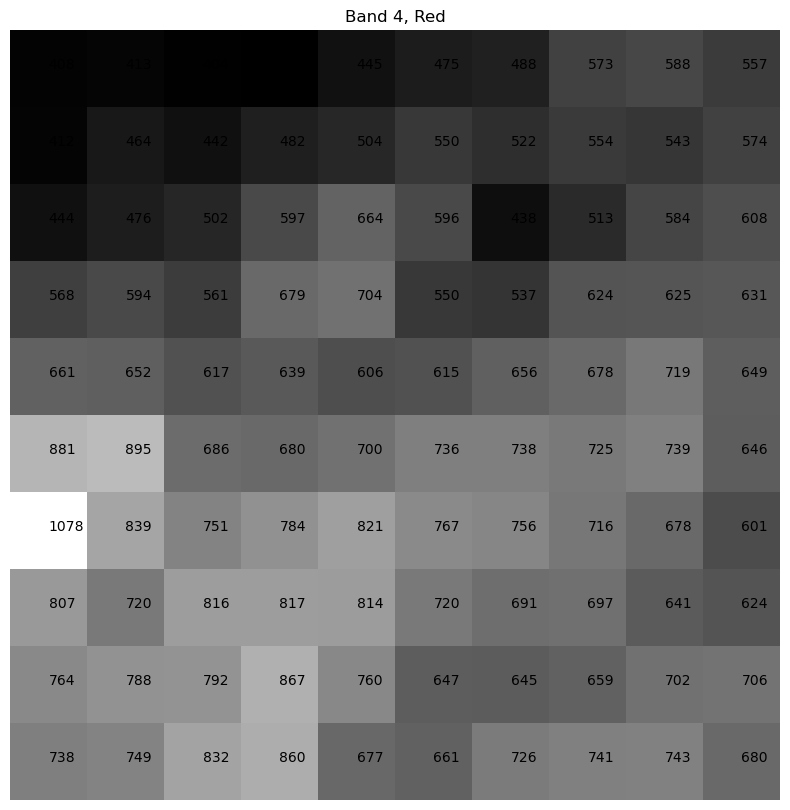

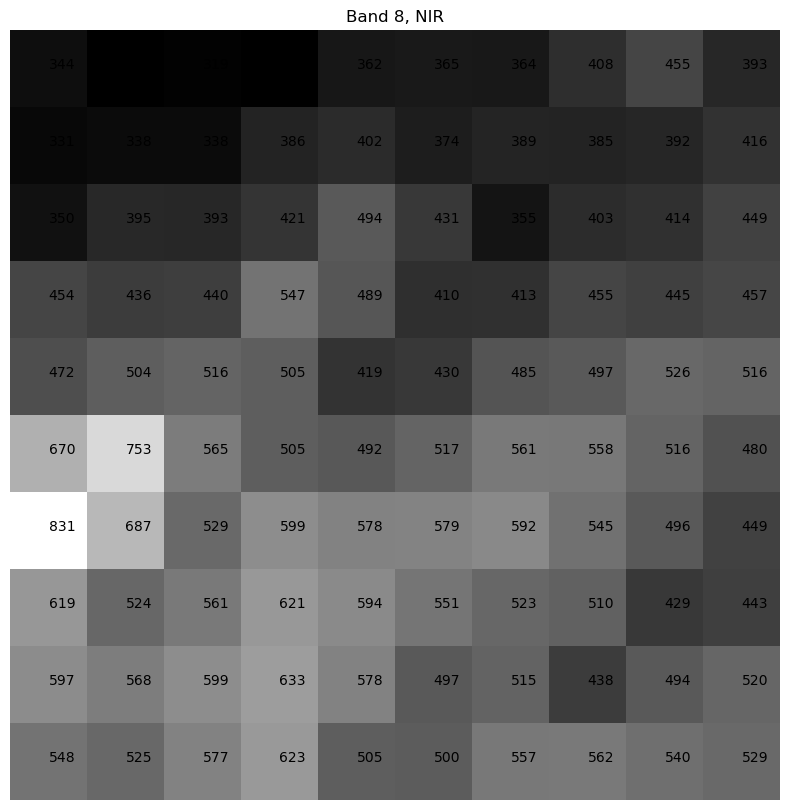

In [ ]:
import rasterio
from rasterio.plot import show
import matplotlib.pyplot as plt
import numpy as np

# Open the satellite image
sat_data = rasterio.open('E:\CTECH\GEOINT\project\SubLandslide2021.tiff')

# Read the individual bands
blue_band_2 = sat_data.read(1)
green_band_3 = sat_data.read(2)
red_band_4 = sat_data.read(3)
NIR_band_8 = sat_data.read(4)

fig=plt.figure(dpi=300)

fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(blue_band_2, cmap='gray')
plt.axis("off")
plt.title("Band 2, Blue")
for i in range(blue_band_2.shape[0]):
    for j in range(blue_band_2.shape[1]):
        ax.text(j,i, str(blue_band_2[i,j])),

fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(green_band_3, cmap='gray')
plt.axis("off")
plt.title("Band 3, Green")
for i in range(green_band_3.shape[0]):
    for j in range(green_band_3.shape[1]):
        ax.text(j,i, str(green_band_3[i,j])),


fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(red_band_4, cmap='gray')
for i in range(red_band_4.shape[0]):
    for j in range(red_band_4.shape[1]):
        ax.text(j,i, str(red_band_4[i,j])),
plt.axis("off")
plt.title("Band 4, Red")

fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(NIR_band_8, cmap='gray')
for i in range(NIR_band_8.shape[0]):
    for j in range(NIR_band_8.shape[1]):
        ax.text(j,i, str(NIR_band_8[i,j])),
plt.axis("off")
plt.title("Band 8, NIR")

Image transformation – computation of Indices - NDVI, NDWI – zonation

Text(0.5, 1.0, 'NDVI Zone')

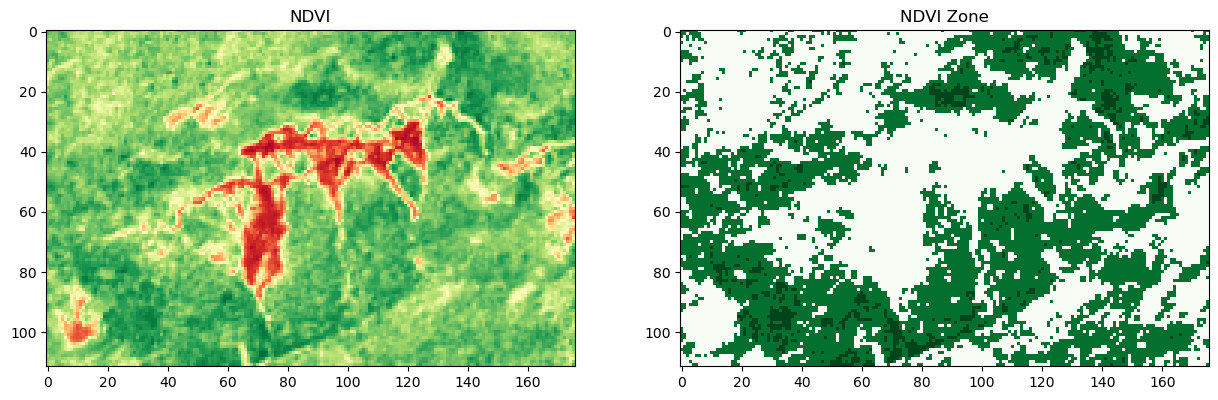

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Load the image
file_path = r'E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif'
with rasterio.open(file_path) as src:
    red = src.read(3)
    nir = src.read(7)
    profile = src.profile

# Calculate NDVI
ndvi = (nir - red) / (nir + red)

def classify_ndvi(ndvi):
    zones = np.zeros_like(ndvi)
    zones[ndvi <= 0.1] = 0
    zones[(ndvi > 0.1)&(ndvi <= 0.2)] = 0
    zones[(ndvi > 0.2)&(ndvi <= 0.3)] = 0
    zones[(ndvi > 0.3)&(ndvi <= 0.4)] = 0
    zones[(ndvi > 0.4)&(ndvi <= 0.5)] = 0
    zones[(ndvi > 0.5)&(ndvi <= 0.6)] = 0
    zones[(ndvi > 0.6)&(ndvi <= 0.7)] = 6
    zones[(ndvi > 0.7)&(ndvi <= 0.8)] = 7
    zones[(ndvi > 0.8)&(ndvi <= 0.9)] = 8
    zones[(ndvi > 0.9)] = 9
    return zones

# ndvi zone
ndvi_zones = classify_ndvi(ndvi)

# Plot the results
fig, ax = plt.subplots(1,2,figsize=(15, 10))

ax[0].imshow(ndvi, cmap='RdYlGn')
ax[0].set_title('NDVI')

ax[1].imshow(ndvi_zones, cmap='Greens')
ax[1].set_title('NDVI Zone')

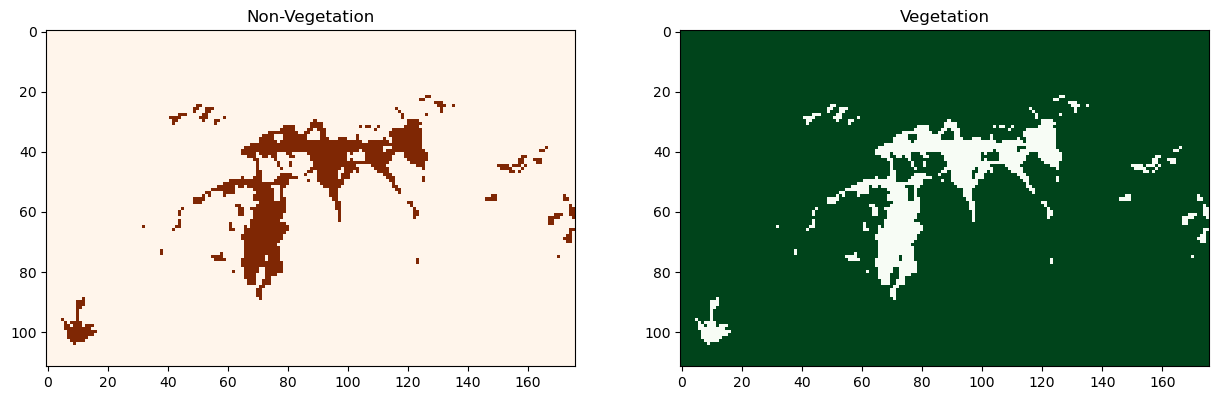

In [ ]:
# Classification for Landslide

def classify_threshold_ndvi(ndvi):
    zones = np.zeros_like(ndvi)
    zones[ndvi <= 0.1] = 0
    zones[(ndvi > 0.1)&(ndvi <= 0.2)] = 0
    zones[(ndvi > 0.2)&(ndvi <= 0.3)] = 0
    zones[(ndvi > 0.3)&(ndvi <= 0.4)] = 1
    zones[(ndvi > 0.4)&(ndvi <= 0.5)] = 1
    zones[(ndvi > 0.5)&(ndvi <= 0.6)] = 1
    zones[(ndvi > 0.6)&(ndvi <= 0.7)] = 1
    zones[(ndvi > 0.7)&(ndvi <= 0.8)] = 1
    zones[(ndvi > 0.8)&(ndvi <= 0.9)] = 1
    zones[(ndvi > 0.9)] = 1
    return zones

# ndvi zone
ndvi_threshold_zones = classify_threshold_ndvi(ndvi)

classification=np.where(ndvi_threshold_zones,0,1)
class1=ndvi_threshold_zones==0
class2=ndvi_threshold_zones==1

# Plot the results
fig, ax = plt.subplots(1,2,figsize=(15, 10))

ax[0].imshow(class1, cmap='Oranges')
ax[0].set_title('Non-Vegetation')

ax[1].imshow(class2, cmap='Greens')
ax[1].set_title('Vegetation')

# NDVI Results

output_tiff_nonveg = r'E:\CTECH\GEOINT\project\Non-Vegetation.tiff'
with rasterio.open(output_tiff_nonveg, 'w', **profile) as dst:
    dst.write(ndvi.astype(rasterio.uint8), 1)
# NDLI zone Results
output_tiff_veg = r'E:\CTECH\GEOINT\project\Vegetation.tiff'
with rasterio.open(output_tiff_veg, 'w', **profile) as dst:
    dst.write(ndvi_zones.astype(rasterio.uint8), 1)

Convert raster to vector file format (.shp, .Geojson) based on specific features

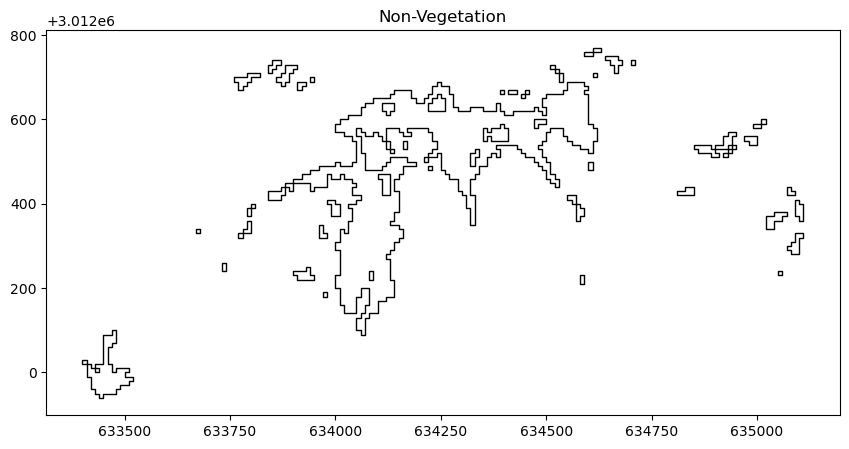

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.features import shapes

# Extract shapes (polygons) from the landslide raster
mask = class2.astype(np.uint8)
results = (
    {'properties': {'raster_val': v}, 'geometry': s}
    for i, (s, v)
    in enumerate(shapes(mask, mask=mask, transform=src.transform))
)
# Convert the shapes to a GeoDataFrame
geoms = list(results)
gdf1 = gpd.GeoDataFrame.from_features(geoms, crs=src.crs)

# Save the GeoDataFrame as a shapefile
output_shapefile = "Non -Vegetation.shp"
gdf1.to_file(output_shapefile)

#------------------------------------------------------------------------------
# Extract shapes (polygons) from the landslide raster
mask = class1.astype(np.uint8)
results = (
    {'properties': {'raster_val': v}, 'geometry': s}
    for i, (s, v)
    in enumerate(shapes(mask, mask=mask, transform=src.transform))
)
# Convert the shapes to a GeoDataFrame
geoms = list(results)
gdf2 = gpd.GeoDataFrame.from_features(geoms, crs=src.crs)

# Save the GeoDataFrame as a shapefile
output_shapefile = 'Vegetation.shp'
gdf2.to_file(output_shapefile)

#-------------------------------------------------------------------------------
# Plot the results
fig, ax = plt.subplots(1,1, figsize=(20,5))
gdf2.boundary.plot(ax=ax, edgecolor='black',linewidth=1)
plt.title('Non-Vegetation')
plt.show()

In [ ]:
import geopandas as gpd

# Define the input shapefile path and the output GeoJSON file path
shapefile_path = "E:\CTECH\GEOINT\project\Vegetation.shp"

# Load the shapefile using GeoPandas
gdf = gpd.read_file(shapefile_path)

# Convert the GeoDataFrame to GeoJSON and save it to a file
geojson_path = 'SentinelTinkitamDEC2020_LANDSLIDE.geojson'
gdf.to_file(geojson_path, driver='GeoJSON')

<>:4: SyntaxWarning: invalid escape sequence '\C'
<>:4: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_8516\2947162551.py:4: SyntaxWarning: invalid escape sequence '\C'
  shapefile_path = "E:\CTECH\GEOINT\project\Vegetation.shp"


Image classification – Supervised & Unsupervised – zonation

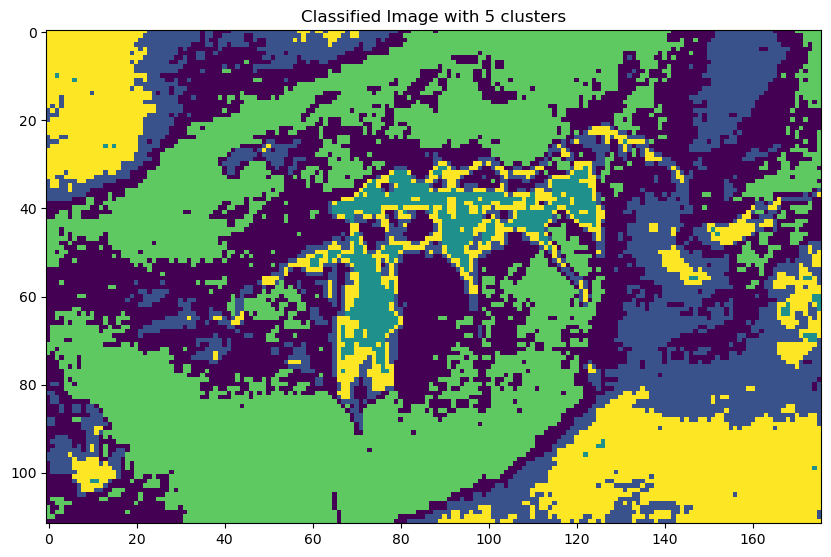

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Step 1: Open the image using rasterio
with rasterio.open(r'E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif') as src:
    img = src.read([1,2])
    profile = src.profile
    # Transpose to get the shape (height, width, bands)
    img = np.transpose(img, (1, 2, 0))

# Step 2: Reshape the image to a 2D array of pixels
n_bands = img.shape[2]
n_rows = img.shape[0]
n_cols = img.shape[1]
pixels = img.reshape((n_rows * n_cols, n_bands))

# Step 3: Perform K-means clustering
n_clusters = 5  # Number of clusters (classes)
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
kmeans.fit(pixels)

# Step 4: Assign each pixel to a cluster
classified_pixels = kmeans.labels_
classified_img = classified_pixels.reshape((n_rows, n_cols))

# Step 5: Plot the classified image
plt.figure(figsize=(10, 10))
plt.imshow(classified_img, cmap='viridis')
# plt.imshow(classified_img, cmap='gray')
plt.title(f'Classified Image with {n_clusters} clusters')
plt.show()

# NDLI Results
output_tiff_classify = 'Unsupervised.tiff'
with rasterio.open(output_tiff_classify, 'w', **profile) as dst:
    dst.write(classified_img.astype(rasterio.uint8), 1)

In [ ]:
import rasterio

image_path = r'E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif'
with rasterio.open(image_path) as src:
    band1 = src.read(1)  # Read the first band
    pixel_value = band1[10, 10]  # Access the pixel value at (10, 10)
    print(f"Pixel value at (10, 10): {pixel_value}")

Pixel value at (10, 10): 807


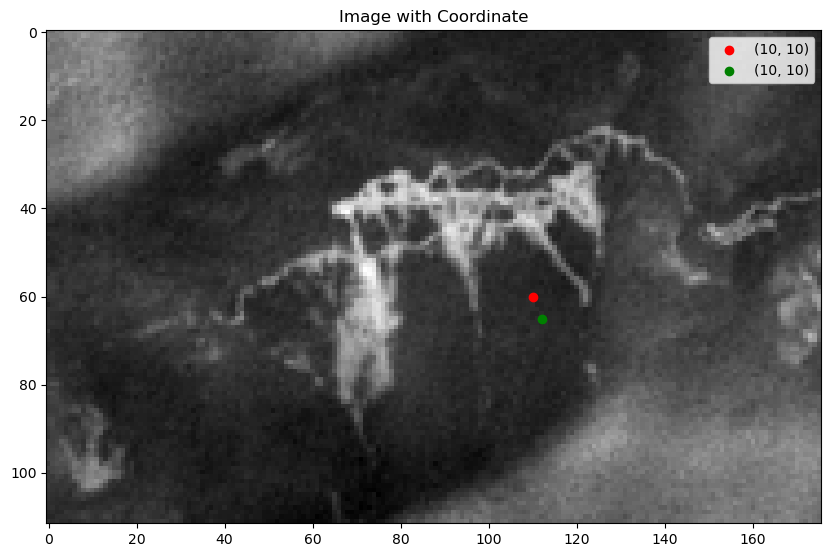

In [ ]:
import matplotlib.pyplot as plt

with rasterio.open(image_path) as src:
    img = src.read(1)  # Read the first band
    plt.figure(figsize=(10, 10))
    plt.imshow(img, cmap='gray')
    plt.scatter(110, 60, c='red', label='(10, 10)') #x,y
    plt.scatter(112, 65, c='green', label='(10, 10)') #x,y
    plt.legend()
    plt.title('Image with Coordinate')
    plt.show()

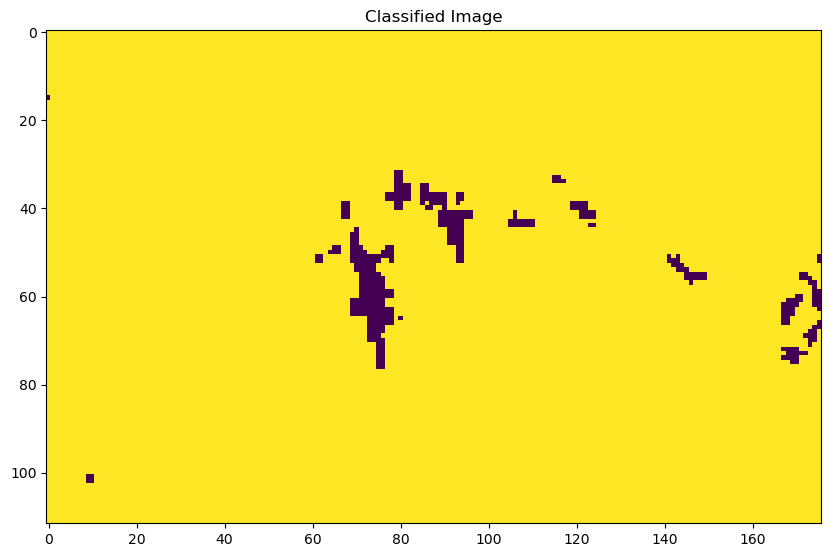

Classification completed and saved to classified_image.tif


In [ ]:
import rasterio
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# Load Sentinel-2 image
def load_image(image_path):
    with rasterio.open(image_path) as src:
        bands = [src.read(i) for i in range(1, src.count + 1)]
        profile = src.profile
    return np.stack(bands, axis=-1), profile

# Extract training samples
def extract_samples(image, training_data, num_bands):
    samples = []
    labels = []
    for label, coords in training_data.items():
        for coord in coords:
            x, y = coord
            sample = image[y, x, :]
            samples.append(sample)
            labels.append(label)
    return np.array(samples), np.array(labels)

# Load image
image_path = r'E:\CTECH\GEOINT\project\SentinelTinkitamAPR2021.tif'
image, profile = load_image(image_path)

# Define training data (for example purposes, this should be replaced with actual coordinates and labels)
training_data = {
    1: [(70, 60), (70, 65), (71,64)],  # Class 1
    2: [(110, 60), (112, 65),(112,70)],   # Class 2

}

# Extract samples and labels
num_bands = image.shape[2]
samples, labels = extract_samples(image, training_data, num_bands)

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(samples, labels, test_size=0.3, random_state=42)

# Train classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# Predict on the entire image
def classify_image(image, classifier):
    height, width, num_bands = image.shape
    flat_image = image.reshape(-1, num_bands)
    flat_prediction = classifier.predict(flat_image)
    return flat_prediction.reshape(height, width)

classified_image = classify_image(image, clf)

# Display results
plt.figure(figsize=(10, 10))
plt.imshow(classified_image, cmap='viridis')
#plt.colorbar()
plt.title('Classified Image')
plt.show()

# Save classified image
output_path = 'classified_image.tif'
with rasterio.open(output_path, 'w', driver='GTiff', height=image.shape[0], width=image.shape[1],
                   count=1, dtype=classified_image.dtype, crs=profile['crs'], transform=profile['transform']) as dst:
    dst.write(classified_image, 1)

print("Classification completed and saved to", output_path)

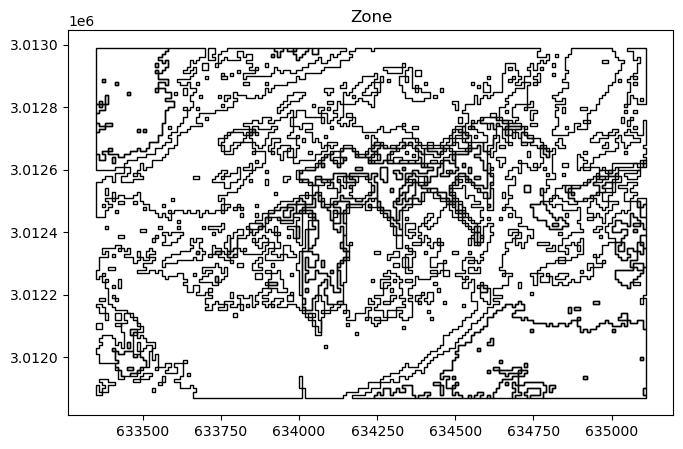

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.features import shapes

# Extract shapes (polygons) from the landslide raster
mask = classified_img.astype(np.uint8)
results = (
    {'properties': {'raster_val': v}, 'geometry': s}
    for i, (s, v)
    in enumerate(shapes(mask, mask=mask, transform=src.transform))
)
# Convert the shapes to a GeoDataFrame
geoms = list(results)
gdf_Uclass = gpd.GeoDataFrame.from_features(geoms, crs=src.crs)

# Save the GeoDataFrame as a shapefile
output_shapefile = 'Uclassification.shp'
gdf_Uclass.to_file(output_shapefile)

#------------------------------------------------------------------------------
# Plot the results
fig, ax = plt.subplots(1,1, figsize=(20,5))
gdf_Uclass.boundary.plot(ax=ax, edgecolor='black',linewidth=1)
plt.title('Zone')
plt.show()

In [ ]:
#Classification and assign name

import geopandas as gpd
import os

# Directory paths
input_dir = "E:\CTECH\GEOINT\project"
output_dir = "E:\CTECH\GEOINT\project"
os.makedirs(output_dir, exist_ok=True)

# List of shapefiles
shapefiles = [
    'Uclassification.shp'
]

# Function to set RegionName based on raster_val
def set_region_name(row):
    if row['raster_val'] == 1:
        return 'Landslide : Dry mixed soil and rock debris'
    elif row['raster_val'] == 2:
        return 'Landslide : Wet soil debris'
    elif row['raster_val'] == 3:
        return 'Vegetation: Shrubland'
    elif row['raster_val'] == 4:
        return 'Vegetation: Forest area'
    elif row['raster_val'] == 5:
        return 'Fallow land: Wet eroded soil'
    else:
        return 'Unknown'

# Process each shapefile
for shp in shapefiles:
    # Read shapefile
    filepath = os.path.join(input_dir, shp)
    gdf = gpd.read_file(filepath)

    # Add 'RegionName' column based on 'raster_val'
    gdf['RegionName'] = gdf.apply(set_region_name, axis=1)

    # Save the modified shapefile
    output_filepath = os.path.join(output_dir, shp)
    gdf.to_file(output_filepath)

<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:8: SyntaxWarning: invalid escape sequence '\C'
<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:8: SyntaxWarning: invalid escape sequence '\C'
C:\Users\ghosh\AppData\Local\Temp\ipykernel_9384\1685879.py:7: SyntaxWarning: invalid escape sequence '\C'
  input_dir = "E:\CTECH\GEOINT\project"
C:\Users\ghosh\AppData\Local\Temp\ipykernel_9384\1685879.py:8: SyntaxWarning: invalid escape sequence '\C'
  output_dir = "E:\CTECH\GEOINT\project"
